# Delta Lake in PySpark

## Basic to Advanced


We will use one sample sales dataset and practically cover:

```text
Delta Lake basics
      ↓
Parquet vs Delta
      ↓
Delta architecture
      ↓
ACID transactions
      ↓
Create / Read Delta table
      ↓
Append
      ↓
History
      ↓
Time Travel
      ↓
UPDATE
      ↓
DELETE
      ↓
Schema Enforcement
      ↓
Schema Evolution
      ↓
MERGE / UPSERT
      ↓
Retention + VACUUM
      ↓
Partitioning
      ↓
Production best practices
```

# 1. What is Delta Lake?

Delta Lake is a transactional storage layer built on top of Parquet.

The easiest definition is:

```text
Delta Lake = Parquet Data Files + Transaction Log
```

### Architecture

```text
                      DELTA TABLE
                           │
              ┌────────────┴────────────┐
              │                         │
              ▼                         ▼
       Parquet Data Files           _delta_log
              │                         │
        Actual table data        Transaction history
                                       │
                                 Version 0
                                 Version 1
                                 Version 2
```

The data is still physically stored in Parquet files.

The `_delta_log` gives Delta Lake transactional behavior.

# 2. Why Do We Need Delta Lake?

Parquet is excellent for:

- Columnar storage
- Compression
- Analytical reads
- Schema storage

But Parquet alone does not provide full transactional table management.

Example problem:

```text
Old table
   ↓
Delete old data
   ↓
Write new data
   ↓
Job fails halfway
   ↓
Table may become incomplete
```

Delta Lake adds reliability features such as:

- ACID transactions
- UPDATE
- DELETE
- MERGE / UPSERT
- Table history
- Time Travel
- Schema enforcement
- Schema evolution

# 3. Parquet vs Delta Lake

| Feature | Parquet | Delta Lake |
|---|---|---|
| Columnar storage | Yes | Yes |
| Compression | Yes | Yes |
| Schema | Yes | Yes |
| Transaction log | No | Yes |
| ACID | No | Yes |
| UPDATE | Not directly | Yes |
| DELETE | Not directly | Yes |
| MERGE / UPSERT | No | Yes |
| History | No | Yes |
| Time Travel | No | Yes |
| Schema enforcement | Limited | Yes |
| Schema evolution | Limited/manual | Yes |

# 4. ACID Transactions

ACID stands for:

```text
A = Atomicity
C = Consistency
I = Isolation
D = Durability
```

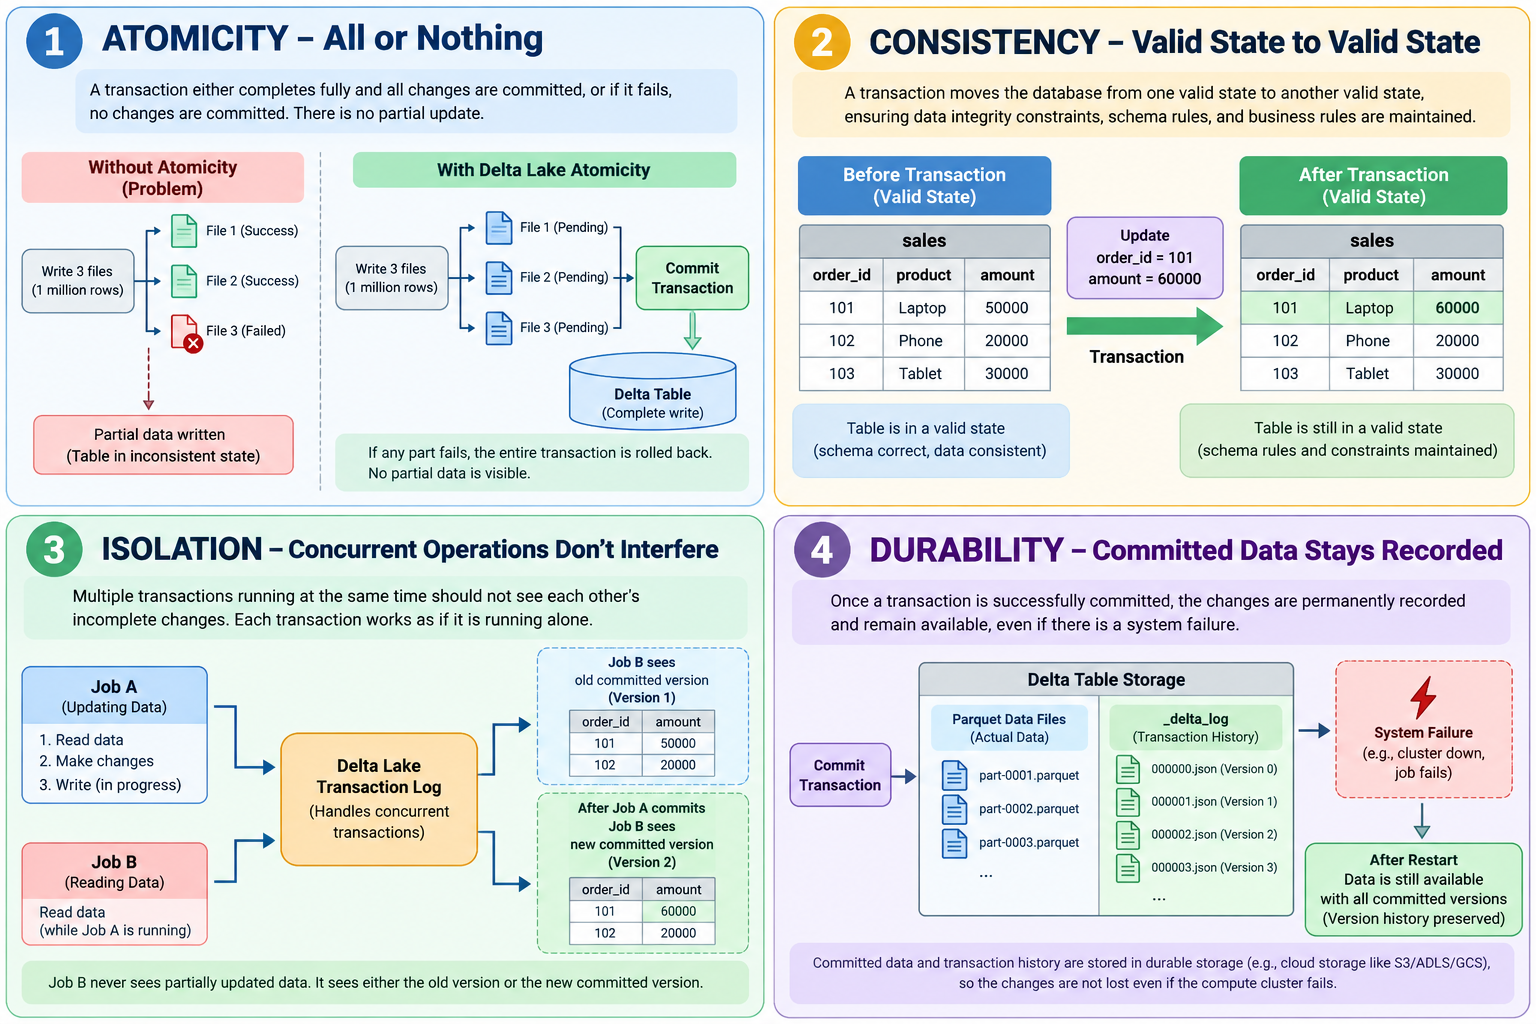

### Atomicity
A transaction either completes fully or is not committed.

```text
Write 1,000 rows
     ↓
Success → all committed
Failure → partial write is not committed
```

### Consistency
The table moves from one valid state to another valid state.

### Isolation
Concurrent jobs should not see half-completed changes.

### Durability
Once a transaction is committed, Delta records that state permanently until retention/cleanup rules remove old files.

# 5. Delta Versions Are NOT Full Copies

Suppose Version 0 uses:

```text
A.parquet
B.parquet
C.parquet
```

If only data represented by `B.parquet` changes, Delta may create:

```text
Version 0 → A + B  + C
Version 1 → A + B2 + C
```

So Delta does not create a complete copy of the full table for every version.

It tracks which files belong to each committed version.

# 6. Check PySpark Version

In [1]:
import pyspark

print("PySpark version:", pyspark.__version__)

PySpark version: 4.1.2


# 7. Import Delta Lake

If this import fails, install a Delta package compatible with your Spark version.

``` pip install delta-spark```

In [2]:
import delta

print("Delta package imported successfully.")

Delta package imported successfully.


# 8. Windows Local Environment Setup

In [3]:
import os
import sys

os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
os.environ["SPARK_LOCAL_IP"] = "127.0.0.1"
os.environ["SPARK_LOCAL_HOSTNAME"] = "localhost"
os.environ["HADOOP_HOME"] = "C:/hadoop"
os.environ["PATH"] = os.environ["HADOOP_HOME"] + "/bin;" + os.environ["PATH"]

# 9. Create Delta-enabled SparkSession

Delta must be configured while creating the SparkSession.

In [4]:
from pyspark.sql import SparkSession
from delta import configure_spark_with_delta_pip

builder = (
    SparkSession.builder
    .appName("Delta_Lake_Theory_Practical")
    .master("local[1]")
    .config("spark.python.worker.reuse", "false")
    .config("spark.driver.host", "127.0.0.1")
    .config("spark.driver.bindAddress", "127.0.0.1")
    .config("spark.sql.extensions", "io.delta.sql.DeltaSparkSessionExtension")
    .config("spark.sql.catalog.spark_catalog", "org.apache.spark.sql.delta.catalog.DeltaCatalog")
)

spark = configure_spark_with_delta_pip(builder).getOrCreate()

spark.sparkContext.setLogLevel("ERROR")

print("Spark version:", spark.version)

Spark version: 4.1.2


# 10. Create Sample Sales Data

We will use this dataset throughout the notebook.

Columns:

```text
order_id
customer_name
city
amount
```

In [5]:
sales_data = [
    (101, "Amit",  "Delhi",  55000),
    (102, "Priya", "Mumbai", 30000),
    (103, "Ravi",  "Delhi",  25000),
    (104, "Neha",  "Pune",   60000)
]

sales_df = spark.createDataFrame(
    sales_data,
    ["order_id", "customer_name", "city", "amount"]
)

sales_df.show()
sales_df.printSchema()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 25000|
|     104|         Neha|  Pune| 60000|
+--------+-------------+------+------+

root
 |-- order_id: long (nullable = true)
 |-- customer_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- amount: long (nullable = true)



# 11. Define Delta Table Path

In [6]:
from pathlib import Path

base_path = Path("delta_demo")
delta_path = base_path / "sales"

print("Delta path:", delta_path.resolve())

Delta path: E:\data\Documents\Data_Engineering\Module4-Pyspark\delta_demo\sales


# 12. Write the First Delta Table

We use:

```python
.format("delta")
```

to tell Spark that this is a Delta table.

In [7]:
(
    sales_df.write
    .format("delta")
    .mode("overwrite")
    .save(str(delta_path))
)

print("Initial Delta table created.")

Initial Delta table created.


## What Happened Internally?

```text
DataFrame
   ↓
Parquet files written
   ↓
Transaction prepared
   ↓
_delta_log updated
   ↓
Version 0 committed
```

# 13. Read the Delta Table

In [9]:
current_df = (
    spark.read
    .format("delta")
    .load(str(delta_path))
)

current_df.show()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 25000|
|     104|         Neha|  Pune| 60000|
+--------+-------------+------+------+



# 14. Inspect Delta Folder

In [10]:
for item in sorted(delta_path.iterdir()):
    print(item.name)

.part-00000-810402a5-826d-475a-b54e-fc289a921c48-c000.snappy.parquet.crc
_delta_log
part-00000-810402a5-826d-475a-b54e-fc289a921c48-c000.snappy.parquet


You should see:

```text
part-....parquet
_delta_log
```

# 15. Inspect `_delta_log`

In [11]:
delta_log_path = delta_path / "_delta_log"

for item in sorted(delta_log_path.iterdir()):
    print(item.name)

.00000000000000000000.crc.crc
.00000000000000000000.json.crc
00000000000000000000.crc
00000000000000000000.json
_staged_commits


The numbered files represent Delta transaction versions.

Example:

```text
00000000000000000000.json → Version 0
00000000000000000001.json → Version 1
00000000000000000002.json → Version 2
```

# 16. Append New Records

In [12]:
new_orders_df = spark.createDataFrame(
    [
        (105, "Karan",  "Delhi",  35000),
        (106, "Simran", "Mumbai", 45000)
    ],
    ["order_id", "customer_name", "city", "amount"]
)

new_orders_df.show()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     105|        Karan| Delhi| 35000|
|     106|       Simran|Mumbai| 45000|
+--------+-------------+------+------+



In [13]:
(
    new_orders_df.write
    .format("delta")
    .mode("append")
    .save(str(delta_path))
)

print("Append completed.")

Append completed.


In [14]:
current_df = (
    spark.read
    .format("delta")
    .load(str(delta_path))
)

current_df.show()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 25000|
|     104|         Neha|  Pune| 60000|
|     105|        Karan| Delhi| 35000|
|     106|       Simran|Mumbai| 45000|
+--------+-------------+------+------+



# 17. DeltaTable API

`DeltaTable` gives us Delta-specific operations such as:

- history
- update
- delete
- merge
- vacuum

In [15]:
from delta.tables import DeltaTable

delta_table = DeltaTable.forPath(
    spark,
    str(delta_path)
)


It gives you a DeltaTable object, not a normal DataFrame.
That object gives access to Delta-specific operations such as:

delta_table.history()

delta_table.update(...)

delta_table.delete(...)

delta_table.merge(...)

delta_table.vacuum(...)

# 18. Check Table History

In [16]:
delta_table.history().select("version", "timestamp", "operation","userId").show(truncate=False)

+-------+-----------------------+---------+------+
|version|timestamp              |operation|userId|
+-------+-----------------------+---------+------+
|8      |2026-10-09 23:47:17.332|WRITE    |NULL  |
|7      |2026-10-09 23:45:04.488|WRITE    |NULL  |
|6      |2026-10-08 23:29:23.954|UPDATE   |NULL  |
|5      |2026-10-08 23:26:26.194|WRITE    |NULL  |
|4      |2026-10-08 23:26:18.667|WRITE    |NULL  |
|3      |2026-10-08 23:25:54.458|WRITE    |NULL  |
|2      |2026-10-08 00:08:24.507|UPDATE   |NULL  |
|1      |2026-10-07 23:43:14.914|WRITE    |NULL  |
|0      |2026-10-07 23:36:04.837|WRITE    |NULL  |
+-------+-----------------------+---------+------+



The history may contain operations such as:

```text
WRITE
UPDATE
DELETE
MERGE
```

# 19. Time Travel

Time Travel means reading a previous committed version of a Delta table.

```text
Version 0
   ↓
Version 1
   ↓
Version 2
   ↓
Latest
```

By default, Spark reads the latest version.

Using `versionAsOf`, we can read an older version.

In [17]:
version_0_df = (
    spark.read
    .format("delta")
    .option("versionAsOf", 0)
    .load(str(delta_path))
)

print("Version 0:")
version_0_df.show()

Version 0:
+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 25000|
|     104|         Neha|  Pune| 60000|
+--------+-------------+------+------+



In [18]:
print("Latest version:")

(spark.read
.format("delta")
.load(str(delta_path))).show()

Latest version:
+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 25000|
|     104|         Neha|  Pune| 60000|
|     105|        Karan| Delhi| 35000|
|     106|       Simran|Mumbai| 45000|
+--------+-------------+------+------+



Time Travel is useful for:

- Auditing
- Debugging
- Recovery
- Comparing old vs new data
- Reproducing old reports

# 20. Time Travel by Timestamp

In [19]:
delta_table.history()     .select("version", "timestamp", "operation")     .show(truncate=False)

+-------+-----------------------+---------+
|version|timestamp              |operation|
+-------+-----------------------+---------+
|8      |2026-10-09 23:47:17.332|WRITE    |
|7      |2026-10-09 23:45:04.488|WRITE    |
|6      |2026-10-08 23:29:23.954|UPDATE   |
|5      |2026-10-08 23:26:26.194|WRITE    |
|4      |2026-10-08 23:26:18.667|WRITE    |
|3      |2026-10-08 23:25:54.458|WRITE    |
|2      |2026-10-08 00:08:24.507|UPDATE   |
|1      |2026-10-07 23:43:14.914|WRITE    |
|0      |2026-10-07 23:36:04.837|WRITE    |
+-------+-----------------------+---------+



You can also read a Delta table using a historical timestamp.

Example syntax:

```python
.option("timestampAsOf", "2026-09-27 10:30:00")
```

Use an actual timestamp from your history.

In [20]:
# Replace the timestamp below with a valid timestamp from your history.

timestamp_df = (
    spark.read
    .format("delta")
    .option("timestampAsOf", "2026-10-07 23:43:14.914")
    .load(str(delta_path))
)

timestamp_df.show()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 25000|
|     104|         Neha|  Pune| 60000|
|     105|        Karan| Delhi| 35000|
|     106|       Simran|Mumbai| 45000|
+--------+-------------+------+------+



# 21. UPDATE

Suppose Ravi's amount is incorrect.

Current:

```text
25000
```

Correct:

```text
27000
```

In [22]:
delta_table.update(
    condition = "order_id = 103",
    set = { "amount": "27000"} )


In [38]:
spark.read.format("delta")     .load(str(delta_path))     .orderBy("order_id")     .show()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 27000|
|     104|         Neha|  Pune| 60000|
|     105|        Karan| Delhi| 35000|
|     106|       Simran|Mumbai| 45000|
+--------+-------------+------+------+



In [35]:
delta_table.update(
    condition="order_id = 103 AND city = 'Delhi'", # Multiple conditions
    set={
        "amount": "28000"
    }
)

print("Update completed.")

Update completed.


In [36]:
spark.read.format("delta")     .load(str(delta_path))   .orderBy("order_id")     .show()

+--------+-------------+------+------+
|order_id|customer_name|  city|amount|
+--------+-------------+------+------+
|     101|         Amit| Delhi| 55000|
|     102|        Priya|Mumbai| 30000|
|     103|         Ravi| Delhi| 28000|
|     104|         Neha|  Pune| 60000|
|     105|        Karan| Delhi| 35000|
|     106|       Simran|Mumbai| 45000|
+--------+-------------+------+------+



The UPDATE creates a new committed table version.

# 22. DELETE

In [ ]:
delta_table.delete(
    condition="order_id = 106"
)

print("Delete completed.")

In [ ]:
spark.read.format("delta")     .load(str(delta_path))     .orderBy("order_id")     .show()

# 23. History After UPDATE and DELETE

In [25]:
delta_table.history()     .select("version", "timestamp", "operation")     .show(truncate=False)

+-------+-----------------------+---------+
|version|timestamp              |operation|
+-------+-----------------------+---------+
|9      |2026-10-09 23:52:21.49 |WRITE    |
|8      |2026-10-09 23:47:17.332|WRITE    |
|7      |2026-10-09 23:45:04.488|WRITE    |
|6      |2026-10-08 23:29:23.954|UPDATE   |
|5      |2026-10-08 23:26:26.194|WRITE    |
|4      |2026-10-08 23:26:18.667|WRITE    |
|3      |2026-10-08 23:25:54.458|WRITE    |
|2      |2026-10-08 00:08:24.507|UPDATE   |
|1      |2026-10-07 23:43:14.914|WRITE    |
|0      |2026-10-07 23:36:04.837|WRITE    |
+-------+-----------------------+---------+



# 24. Schema Enforcement

Existing schema:

```text
order_id
customer_name
city
amount
```

Suppose new incoming data contains:

```text
country
```

This is a schema change.

Delta can block unintended schema changes.

In [26]:
schema_change_df = spark.createDataFrame(
    [
        (107, "Rahul", "Delhi", 50000, "India")
    ],
    ["order_id", "customer_name", "city", "amount", "country"]
)

schema_change_df.printSchema()
schema_change_df.show()

root
 |-- order_id: long (nullable = true)
 |-- customer_name: string (nullable = true)
 |-- city: string (nullable = true)
 |-- amount: long (nullable = true)
 |-- country: string (nullable = true)

+--------+-------------+-----+------+-------+
|order_id|customer_name| city|amount|country|
+--------+-------------+-----+------+-------+
|     107|        Rahul|Delhi| 50000|  India|
+--------+-------------+-----+------+-------+



The next example is intentionally commented because it may fail due to schema enforcement.

Uncomment it if you want to observe the error.

In [ ]:
# (
#     schema_change_df.write
#     .format("delta")
#     .mode("append")
#     .save(str(delta_path))
# )

# 25. Schema Evolution

If the schema change is intentional, we can allow it with:

```text
mergeSchema = true
```

In [30]:
(
    schema_change_df.write
    .format("delta")
    .mode("append")
    .option("mergeSchema", "true")
    .save(str(delta_path))
)

print("Schema evolution completed.")

Schema evolution completed.


In [35]:
delta_table = DeltaTable.forPath( # we have to update delta_table object before further tasks
    spark,
    str(delta_path)
)

Old rows may contain `NULL` for the newly added `country` column.

# 26. MERGE / UPSERT

UPSERT means:

```text
UPDATE + INSERT
```

Decision flow:

```text
Incoming record
      ↓
Does business key already exist?
      ↓
 ┌────┴─────┐
 │          │
YES         NO
 │          │
UPDATE      INSERT
```

We will send:

```text
102 → already exists, so UPDATE
108 → new record, so INSERT
```

In [34]:
incoming_df = spark.createDataFrame(
    [
        (102, "Priya",  "Mumbai", 38000, "India"),
        (108, "Anjali", "Pune",   42000, "India")
    ],
    ["order_id", "customer_name", "city", "amount", "country"]
)

incoming_df.show()

+--------+-------------+------+------+-------+
|order_id|customer_name|  city|amount|country|
+--------+-------------+------+------+-------+
|     102|        Priya|Mumbai| 38000|  India|
|     108|       Anjali|  Pune| 42000|  India|
+--------+-------------+------+------+-------+



# 27. Execute MERGE

In [36]:
(
    delta_table.alias("target")
    .merge(
           incoming_df.alias("source"),
           "target.order_id = source.order_id"
    )
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute()

)
print("merge done")
                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                


merge done


In [ ]:
(
    delta_table.alias("target")
    .merge(
        incoming_df.alias("source"),
        "target.order_id = source.order_id"
    )
    .whenMatchedUpdateAll()
    .whenNotMatchedInsertAll()
    .execute()
)

print("MERGE completed.")

In [ ]:
spark.read.format("delta")     .load(str(delta_path))     .orderBy("order_id")     .show()

Expected:

```text
order_id 102 → updated
order_id 108 → inserted
```

# 28. Check MERGE in History

In [37]:
delta_table.history()     .select("version", "timestamp", "operation")     .show(truncate=False)

+-------+-----------------------+---------+
|version|timestamp              |operation|
+-------+-----------------------+---------+
|12     |2026-10-10 00:26:08.07 |MERGE    |
|11     |2026-10-10 00:21:22.71 |WRITE    |
|10     |2026-10-09 23:56:53.194|WRITE    |
|9      |2026-10-09 23:52:21.49 |WRITE    |
|8      |2026-10-09 23:47:17.332|WRITE    |
|7      |2026-10-09 23:45:04.488|WRITE    |
|6      |2026-10-08 23:29:23.954|UPDATE   |
|5      |2026-10-08 23:26:26.194|WRITE    |
|4      |2026-10-08 23:26:18.667|WRITE    |
|3      |2026-10-08 23:25:54.458|WRITE    |
|2      |2026-10-08 00:08:24.507|UPDATE   |
|1      |2026-10-07 23:43:14.914|WRITE    |
|0      |2026-10-07 23:36:04.837|WRITE    |
+-------+-----------------------+---------+



# 29. Why MERGE Is Important in Production

Suppose your target contains:

```text
100 million rows
```

Today's source contains:

```text
500,000 changed/new rows
```

Instead of rewriting the full target:

```text
Read incremental records
        ↓
Clean / validate
        ↓
MERGE into Delta
        ↓
Matched → UPDATE
New     → INSERT
```

This is one of the most common Delta Lake ETL patterns.

# 30. Idempotency

An idempotent pipeline should ideally produce the same business result when the same input is processed again.

MERGE helps when you have a stable business key:

```text
order_id
customer_id
transaction_id
```

If order `102` arrives again, it can be updated instead of blindly inserted as a duplicate.

# 31. Retention and Time Travel

Historical versions may require old physical data files.

Trade-off:

```text
Long retention
      ↓
More historical recovery
      ↓
More storage

Short retention
      ↓
Less storage
      ↓
Less historical recovery
```

# 32. VACUUM

`VACUUM` removes old physical files that:

1. are no longer referenced by the current table state, and
2. are older than the retention threshold.

Example for 7 days:

```text
7 × 24 = 168 hours
```

Python:

```python
delta_table.vacuum(168)
```

Important:

```text
VACUUM does not directly delete "Version 0".
```

It removes old physical files.

If an older Time Travel version needs those files, that version may no longer be readable afterward.

# 33. Practical VACUUM Example

In [38]:
# Safe demonstration using 7-day retention.
# Because our sample table is new, this will usually remove nothing.

vacuum_result = delta_table.vacuum(168)

print("VACUUM command completed.")

VACUUM command completed.


## Important Production Warning

Do not aggressively reduce retention just to save storage.

Short retention can affect:

- Long-running jobs
- Streaming jobs
- Auditing
- Recovery
- Time Travel

# 34. Transaction Log vs Historical Data Files

These are different concepts.

```text
Transaction Log
      ↓
Tracks metadata and table versions

Historical Data Files
      ↓
Contain the actual old records needed by old versions
```

Time Travel needs the required historical metadata **and** the required historical data files.

# 35. Partitioning Delta Tables

Delta tables can also be physically partitioned.

Example:

```text
partitionBy("city")
```

In [39]:
partitioned_path = base_path / "sales_partitioned"

(
    sales_df.write
    .format("delta")
    .mode("overwrite")
    .partitionBy("city")
    .save(str(partitioned_path))
)

print("Partitioned Delta table created.")

Partitioned Delta table created.


The folder structure may look like:

```text
sales_partitioned/
├── city=Delhi/
├── city=Mumbai/
├── city=Pune/
└── _delta_log/
```

# 36. Partition Pruning

In [ ]:
from pyspark.sql.functions import col

partitioned_df = (
    spark.read
    .format("delta")
    .load(str(partitioned_path))
)

partitioned_df.filter(
    col("city") == "Delhi"
).show()

When Spark can skip unrelated partitions, this is called:

```text
Partition Pruning
```

# 37. Small Files Problem

Frequent small writes can create:

```text
1 MB
2 MB
500 KB
3 MB
...
```

Too many small files increase:

- File-open overhead
- Metadata overhead
- Scheduling overhead
- Query latency

# 38. Compaction / OPTIMIZE Concept

Some Delta platforms support compaction commands such as:

```sql
OPTIMIZE table_name
```

Concept:

```text
Many small files
      ↓
Compaction
      ↓
Fewer larger files
```

Exact syntax depends on the Delta platform/runtime.

# 39. Bronze / Silver / Gold Architecture

A common Lakehouse pattern:

```text
Source Systems
      ↓
BRONZE
Raw Delta data
      ↓
SILVER
Clean + validated data
      ↓
GOLD
Business-ready data
      ↓
BI / ML / Reporting
```

# 40. Production Best Practices

1. Use a stable business key for MERGE.
2. Avoid uncontrolled schema evolution.
3. Monitor the small-files problem.
4. Partition only when it improves query pruning.
5. Avoid extremely high-cardinality partition columns.
6. Use Delta history for auditing.
7. Keep enough retention for recovery.
8. Never manually delete Delta data files.
9. Never manually delete `_delta_log`.
10. Validate row counts before and after important MERGE operations.

# 41. Interview Questions

### What is Delta Lake?
Delta Lake uses Parquet files plus a transaction log to provide transactional table capabilities.

### What is `_delta_log`?
The transaction-log directory that tracks Delta table metadata and committed changes.

### What is Time Travel?
Reading a previous committed table version.

### Does Delta store a full table copy for every version?
No. It tracks file-level table states and retains historical files as required.

### What is VACUUM?
Removal of old unreferenced physical files after a retention period.

### What is UPSERT?
Update matching rows and insert non-matching rows.

### Schema enforcement vs schema evolution?
Enforcement blocks unintended changes; evolution intentionally allows approved schema changes.

# Final Concept Map

```text
                           DELTA LAKE
                               │
             ┌─────────────────┼─────────────────┐
             │                 │                 │
             ▼                 ▼                 ▼
          Parquet          _delta_log           ACID
             │                 │                 │
        Actual Data       Table Versions     Reliability
                               │
                  ┌────────────┼─────────────┐
                  ▼            ▼             ▼
                History    Time Travel     Transactions
                                              │
                               ┌──────────────┼──────────────┐
                               ▼              ▼              ▼
                             UPDATE         DELETE          MERGE
                                                              │
                                                              ▼
                                                            UPSERT

Historical Files
      ↓
Retention Window
      ↓
VACUUM
      ↓
Storage Cleanup
```

# Final Summary

Remember:

```text
Delta Lake = Parquet + Transaction Log
```

The most important practical Delta concepts are:

```text
ACID
History
Time Travel
UPDATE
DELETE
Schema Enforcement
Schema Evolution
MERGE / UPSERT
Retention
VACUUM
Partitioning
```

The key production use case is reliable incremental data processing using `MERGE`.

# Stop SparkSession

In [ ]:
spark.stop()